# Dependence on initial parameters (Fig. 6)

- The absolute errors of the 50 parameter sets are averaged within each participant, so that each condition has one value per participant (n = 18).
- The mean and the standard error in the figure are computed from these 18 participant means.
- `participant_mean.csv` is the input of the statistical tests in `stats_init_param_participant.ipynb`.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
%matplotlib inline

In [2]:
p_num = 50
user_num = 18
param_lis = ["param0", "param1", "param2", "param3", "param4"]
method_dict = {"I-VT": "ivtl_80deg_160ms", "I-DT": "idt_07deg_160ms", "I-VDT": "ivdt_80deg_07deg_160ms"}
scene_lis = ["office", "supermarket"]

## Load results

`errors[(scene, method)]` has the shape (range, parameter set, participant) = (5, 50, 18).

In [3]:
errors = {}
for scene in scene_lis:
    for method, folder in method_dict.items():
        err = np.empty([len(param_lis), p_num, user_num])
        for i, param in enumerate(param_lis):
            for p in range(p_num):
                err[i, p] = pd.read_csv(f"../param/exp_init_param/{folder}/{param}/{p}/result_{scene}.csv")["error"].values
        errors[(scene, method)] = err

errors[("office", "I-VDT")].shape

(5, 50, 18)

## Aggregate within each participant

Average the 50 parameter sets for each participant: (5, 50, 18) -> (5, 18).

In [4]:
user_mean = {key: err.mean(axis=1) for key, err in errors.items()}

# Save participant-level values for the statistical tests
rows = []
for (scene, method), val in user_mean.items():
    for i in range(len(param_lis)):
        for u in range(user_num):
            rows.append({"scene": scene, "method": method, "range": i + 1, "participant": u, "error": val[i, u]})
user_mean_df = pd.DataFrame(rows)
os.makedirs("../param/wilcoxon_holm", exist_ok=True)
user_mean_df.to_csv("../param/wilcoxon_holm/participant_mean.csv", index=False)
user_mean_df.head()

,scene,method,range,participant,error
0,office,I-VT,1,0,1.416499
1,office,I-VT,1,1,4.689407
2,office,I-VT,1,2,2.086822
3,office,I-VT,1,3,5.393945
4,office,I-VT,1,4,3.689665


## Mean and standard error across participants (n = 18)

The standard error uses the unbiased standard deviation (ddof=1) of the 18 participant means.

In [5]:
mean = {key: val.mean(axis=1) for key, val in user_mean.items()}
se = {key: val.std(axis=1, ddof=1) / np.sqrt(val.shape[1]) for key, val in user_mean.items()}

## Figure

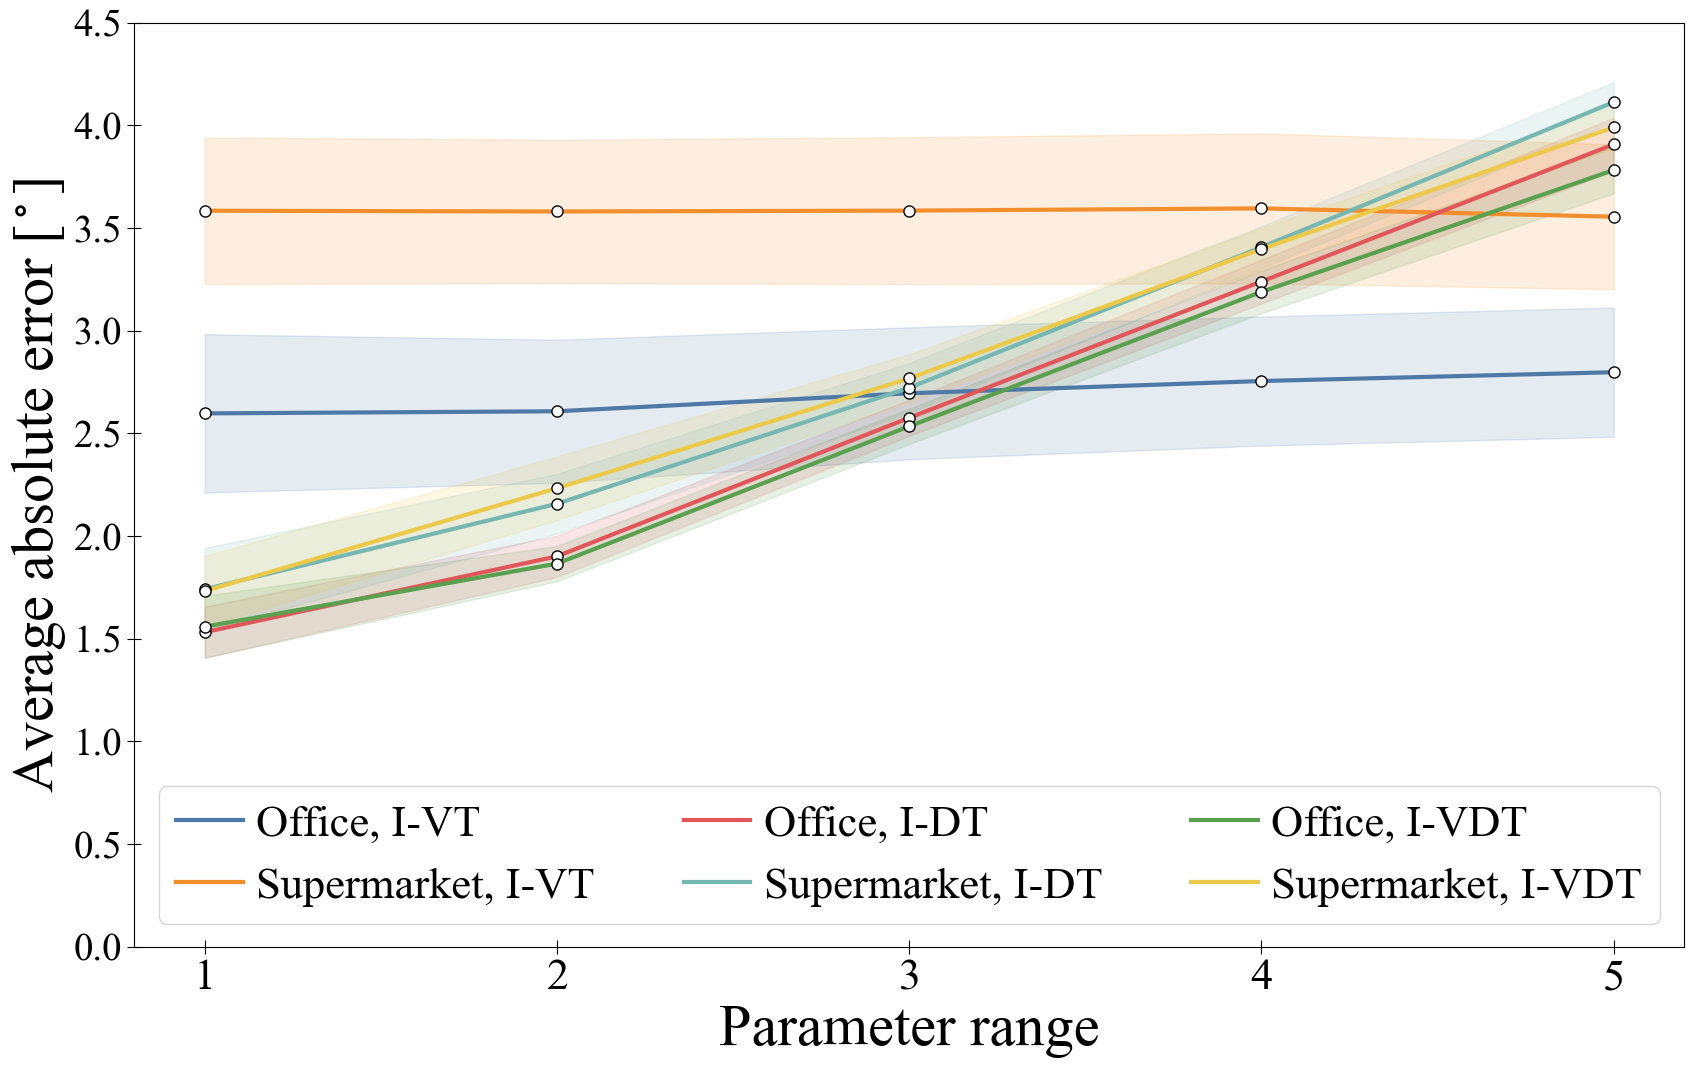

In [6]:
font_size = 42

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.prop_cycle']  = cycler(color=['#4E79A7', '#F28E2B', '#E15759', '#76B7B2','#59A14E', '#EDC949','#B07AA2','#FF9DA7','#9C755F','#BAB0AC'])
os.makedirs("../figures", exist_ok=True)

fig = plt.figure(figsize=(20, 12))
fig.patch.set_facecolor("white")

x_lis = range(len(param_lis))
color_idx = 0
for method in method_dict:
    for scene in scene_lis:
        m = mean[(scene, method)]
        s = se[(scene, method)]
        c = f"C{color_idx}"
        plt.plot(x_lis, m, c=c, label=f"{scene.capitalize()}, {method}", linewidth=3)
        plt.errorbar(x_lis, m, fmt="o", color="white", markeredgecolor="k", ecolor="k", markersize=8)
        plt.fill_between(x_lis, m+s, m-s, color=c, alpha=0.15)
        color_idx += 1

label_x = ["1", "2", "3", "4", "5"]
plt.xticks([i for i in x_lis], label_x, fontsize=32)
plt.yticks(fontsize=28)
plt.tick_params(direction = "inout", length=10)

plt.ylim(0.0, 4.5)
plt.xlabel("Parameter range", size=font_size)
plt.ylabel(r"Average absolute error [$^\circ$]", size=font_size)
plt.legend(loc='lower center', ncol=3, handlelength=1.5, handletextpad=0.3, fontsize=32)
plt.savefig("../figures/param_result.png", bbox_inches='tight')
plt.savefig("../figures/param_result.pdf", bbox_inches='tight')
plt.show()